# 10주차 완성 예제 — 교통 데이터의 시각화
인공지능과 데이터 활용 · 2026-2학기 · 120분

**오늘의 질문:** 사람이 많이 타고 내리는 역은 열차도 가장 붐빌까? AI 혼잡도 예측은 무엇을 보고 예측할까?

| 단계 | 내용 | 결과물 |
|---|---|---|
| 0~1 | 준비, 데이터 3종 불러오기 | 행·열 수 확인 |
| 2~3 | 데이터 구조 이해, 가로→세로 변환 | `long` 표 |
| 4~7 | 막대·선·히트맵 시각화 | 그림 4장 |
| ✍️ | 기록 1 (Q1~Q4) | 답변 |
| 8~9 | 실제 혼잡도 데이터와 이용량 비교 | 그림 2장 |
| 10 | AI 혼잡도 예측 체험 | MAE·그림 2장 |
| 11 | 서울 실시간 도시데이터(AI 예측 서비스) 비교 | 조회 기록 |
| ✍️ | 기록 2 (Q5~Q8), 제출 ZIP | ZIP |

**사용 방법:** `파일 → Drive에 사본 저장` 후 **위에서부터 한 셀씩 ▶ 실행**합니다. 런타임을 다시 시작했다면 0단계부터 다시 실행합니다. API 키는 필요 없습니다.

> 이 노트북은 모든 셀을 실행한 **완성 예제**입니다. 기록 셀에 예시 답변이 들어 있습니다.


## 0단계. 실습 준비 (3분)
그래프에 한글이 보이도록 한글 폰트 패키지를 설치하고, 사용할 도구를 불러옵니다.
- `pandas`: 표 데이터를 다루는 도구 · `matplotlib`: 그래프 도구 · `koreanize_matplotlib`: 그래프 한글 폰트
- 결과 그림과 기록은 `week10_outputs` 폴더에 저장됩니다.

✅ **확인:** `준비 완료`가 출력되면 다음 단계로 갑니다. (설치 메시지가 몇 줄 나올 수 있습니다.)

In [1]:
import subprocess, sys
try:
    import koreanize_matplotlib            # 한글 폰트 설정
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'koreanize-matplotlib'], check=False)
    try:
        import koreanize_matplotlib
    except ImportError:
        print('⚠️ 한글 폰트 설치 실패: 그래프의 한글이 네모로 보일 수 있지만 실습은 계속할 수 있습니다.')

from pathlib import Path
import re, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams['figure.dpi'] = 110
OUT = Path('week10_outputs')
OUT.mkdir(exist_ok=True)
print('준비 완료 · pandas', pd.__version__)

준비 완료 · pandas 3.0.5


## 1단계. 데이터 3종 불러오기 (7분)
| 파일 | 내용 | 출처 |
|---|---|---|
| `subway_hourly_202609.csv` | 2026년 9월 **호선·역·시간대별 승차/하차 인원**(한 달 합계) | 서울 열린데이터광장 OA-12252 |
| `subway_congestion_20250331.csv` | **열차 혼잡도**(%, 30분 단위, 평일/토/일, 방향별) | 서울교통공사·공공데이터포털 15071311 |
| `citydata_places_121.csv` | AI 인구 예측을 제공하는 **서울 주요 121장소** 목록 | 서울 실시간 도시데이터 |

실습 파일은 모두 **수업 Google Drive 폴더**(`강의10주_교통데이터의시각화 → 01_실습데이터`)에 있습니다. 아래 셀은 Drive 파일 ID로 세 파일을 Colab의 `week10_data` 폴더에 **내려받은 뒤** 읽습니다. (Drive 로그인·마운트 불필요, 링크 공개 파일)

| 코드 | 하는 일 |
|---|---|
| `DRIVE_ID` | Drive에 저장된 파일마다 붙은 고유 번호 (Drive 링크 `/d/` 뒤의 문자열) |
| `gdown.download(id=..., output=...)` | Drive 파일을 Colab으로 내려받기 (`gdown`은 Colab에 기본 설치) |
| `pd.read_csv(경로)` | 내려받은 CSV를 표(DataFrame)로 읽기 |

Drive 접속이 일시적으로 안 되면 수업 GitHub 사본으로 자동 전환되고, 그래도 안 되면 업로드 창이 열립니다(노션의 Drive 링크에서 CSV를 받아 올리기).

✅ **확인:** 세 파일 모두 `[Google Drive]`에서 읽혔고 `(621, 52)`, `(1662, 45)`, `(121, 5)`가 출력되어야 합니다.

In [2]:
DRIVE_FOLDER = 'https://drive.google.com/drive/folders/19KLHZYA21T2b5mcW4-_7wZrp7E0s4zHG'   # 01_실습데이터
DRIVE_ID = {
 "subway_hourly_202609.csv": "174hLXWgpoGn32ZcOifmo4aZmR9XXaGL1",
 "subway_congestion_20250331.csv": "1jTFSAgocpPDHgfU0tlwdVul4stXIq9gi",
 "citydata_places_121.csv": "1D5h3N5E-pW3D1vu9RT4a4jDvPGKt0a3B"
}
EXPECTED = {'subway_hourly_202609.csv': (621, 52), 'subway_congestion_20250331.csv': (1662, 45),
            'citydata_places_121.csv': (121, 5)}
BACKUP = 'https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week10/data/'          # Drive 접속 실패 시에만 쓰는 백업
DATA_DIR = Path('week10_data')
DATA_DIR.mkdir(exist_ok=True)

def read_ok(path, name):
    try:
        df = pd.read_csv(path)
        return df if df.shape == EXPECTED[name] else None
    except Exception:
        return None

def load_csv(name):
    path = DATA_DIR / name
    # ① Google Drive에서 내려받기
    try:
        import gdown
        gdown.download(id=DRIVE_ID[name], output=str(path), quiet=True)
    except Exception as e:
        print('  Drive 내려받기 실패:', type(e).__name__)
    df = read_ok(path, name) if path.exists() else None
    if df is not None:
        print('✔ [Google Drive]', name, df.shape)
        return df
    # ② 백업: 수업 GitHub
    df = read_ok(BACKUP + name, name)
    if df is not None:
        df.to_csv(path, index=False, encoding='utf-8-sig')
        print('✔ [GitHub 백업]', name, df.shape)
        return df
    # ③ 직접 업로드
    from google.colab import files
    print(name, '파일을 업로드하세요. (Drive 폴더:', DRIVE_FOLDER, ')')
    up = files.upload()
    return pd.read_csv(list(up.keys())[0])

hourly = load_csv('subway_hourly_202609.csv')
cong   = load_csv('subway_congestion_20250331.csv')
places = load_csv('citydata_places_121.csv')

assert hourly.shape == (621, 52), '승하차 파일의 행·열 수가 다릅니다.'
assert cong.shape == (1662, 45), '혼잡도 파일의 행·열 수가 다릅니다.'
assert places.shape == (121, 5), '장소 목록 파일의 행·열 수가 다릅니다.'
print(hourly.shape, cong.shape, places.shape)

(Colab에서 실행하면 세 줄 모두 '✔ [Google Drive] 파일명 (행, 열)'로 표시됩니다. 이 완성본은 Drive 접근이 막힌 검증 환경에서 실행해 출력을 비웠습니다.)


## 2단계. 데이터 구조 살펴보기 (8분)
데이터를 그리기 전에 **한 행이 무엇을 뜻하는지** 먼저 확인합니다.
- `hourly`의 한 행 = **한 달(2026년 9월) · 한 호선 · 한 역**의 시간대별 승차·하차 인원 합계
- 열은 `04시-05시 승차인원`, `04시-05시 하차인원`, … `03시-04시 하차인원`까지 시간대마다 2개씩 있습니다(24시간 × 2 = 48개 + 사용월·호선명·지하철역·작업일자 4개).
- 같은 역이라도 호선이 다르면 다른 행입니다. 예) `강남`은 2호선 행만 있고 신분당선 강남역은 이 자료에 없습니다(서울시 집계 범위).

✅ **확인:** 강남역 행에서 `08시-09시 하차인원`이 `18시-19시 하차인원`보다 큰가요?

In [3]:
print('호선 수:', hourly['호선명'].nunique(), '/ 행(역) 수:', len(hourly))
print('결측값 개수:', hourly.isna().sum().sum())
display(hourly.head(3))

gangnam = hourly[(hourly['호선명'] == '2호선') & (hourly['지하철역'] == '강남')]
display(gangnam[['사용월', '호선명', '지하철역', '08시-09시 승차인원', '08시-09시 하차인원',
                 '18시-19시 승차인원', '18시-19시 하차인원']])

호선 수: 27 / 행(역) 수: 621
결측값 개수: 0


,사용월,호선명,지하철역,04시-05시 승차인원,04시-05시 하차인원,05시-06시 승차인원,05시-06시 하차인원,06시-07시 승차인원,06시-07시 하차인원,07시-08시 승차인원,...,23시-24시 하차인원,00시-01시 승차인원,00시-01시 하차인원,01시-02시 승차인원,01시-02시 하차인원,02시-03시 승차인원,02시-03시 하차인원,03시-04시 승차인원,03시-04시 하차인원,작업일자
0,202609,1호선,동대문,546,43,9566,2065,9278,6396,16074,...,12407,979,3120,1,284,0,0,0,0,20261003
1,202609,1호선,동묘앞,189,5,2766,971,4131,4952,9302,...,4979,156,2307,0,321,0,0,0,0,20261003
2,202609,1호선,서울역,892,55,12204,12821,40415,66505,119513,...,36930,5380,9351,19,248,0,0,0,0,20261003


,사용월,호선명,지하철역,08시-09시 승차인원,08시-09시 하차인원,18시-19시 승차인원,18시-19시 하차인원
10,202609,2호선,강남,63086,314572,313031,167503


## 3단계. 가로 표 → 세로 표로 바꾸기 (10분)
시간대가 **열 이름**에 들어 있으면 시간별로 묶거나 그래프를 그리기 어렵습니다. `melt`로 시간대 열 48개를 **행으로 내려** `시간`, `구분(승차/하차)`, `인원` 세 열로 정리합니다(이런 형태를 *tidy* 데이터라고 합니다).

| 코드 | 하는 일 |
|---|---|
| `melt(id_vars=..., value_vars=...)` | 고정할 열(사용월·호선명·지하철역)은 두고 시간대 열을 행으로 펼침 |
| `항목.str[:2]` | `'08시-09시 승차인원'` → `'08'` → 정수 8 (08~09시 구간의 시작 시각) |
| `항목.str.contains('승차')` | 승차/하차 구분 만들기 |
| `인원 / 30` | 9월은 30일 → **하루 평균**(명/일)으로 바꾸기 |

✅ **확인:** `long`은 621역 × 48칸 = **29,808행**이고, 변환 전후 인원 합계가 같아야 합니다.

In [4]:
time_cols = [col for col in hourly.columns if col.endswith('인원')]
long = hourly.melt(id_vars=['사용월', '호선명', '지하철역'], value_vars=time_cols,
                   var_name='항목', value_name='인원')
long['시간'] = long['항목'].str[:2].astype(int)
long['구분'] = np.where(long['항목'].str.contains('승차'), '승차', '하차')
DAYS = pd.Period(str(hourly['사용월'].iloc[0]), freq='M').days_in_month   # 9월 = 30일
long['일평균'] = long['인원'] / DAYS
long['역(호선)'] = long['지하철역'] + '(' + long['호선명'] + ')'

assert len(long) == 621 * 48
assert long['인원'].sum() == hourly[time_cols].to_numpy().sum()
print('행 수:', len(long), '/ 달력일 수:', DAYS)
print('9월 전체 승차', f"{long.loc[long['구분']=='승차','인원'].sum():,}", '명 / 하차', f"{long.loc[long['구분']=='하차','인원'].sum():,}", '명')
display(long.head())

행 수: 29808 / 달력일 수: 30
9월 전체 승차 216,589,218 명 / 하차 215,410,189 명


,사용월,호선명,지하철역,항목,인원,시간,구분,일평균,역(호선)
0,202609,1호선,동대문,04시-05시 승차인원,546,4,승차,18.200000,동대문(1호선)
1,202609,1호선,동묘앞,04시-05시 승차인원,189,4,승차,6.300000,동묘앞(1호선)
2,202609,1호선,서울역,04시-05시 승차인원,892,4,승차,29.733333,서울역(1호선)
3,202609,1호선,시청,04시-05시 승차인원,144,4,승차,4.800000,시청(1호선)
4,202609,1호선,신설동,04시-05시 승차인원,321,4,승차,10.700000,신설동(1호선)


## 4단계. 막대그래프 — 이용 인원이 가장 많은 역 TOP 10 (8분)
역(호선)별로 `일평균`을 모두 더해 **하루 평균 승차+하차 인원**을 구하고 큰 순서로 10개를 가로 막대로 그립니다.
- `groupby('역(호선)')['일평균'].sum()` → 역별 합계 · `nlargest(10)` → 상위 10개
- 가로 막대는 역 이름이 길어도 읽기 쉽고, 막대는 **0에서 시작**해야 길이로 크기를 비교할 수 있습니다.

✅ **확인:** 1위 역과 하루 평균 인원(명/일)을 기록 1의 Q1에 적습니다.

,하루 평균 승하차(명/일)
역(호선),
서울역(1호선),160906
잠실(송파구청)(2호선),150573
강남(2호선),148091
홍대입구(2호선),147648
성수(2호선),115309
신림(2호선),106560
구로디지털단지(2호선),105108
을지로입구(2호선),104286
용산(경부선),103084


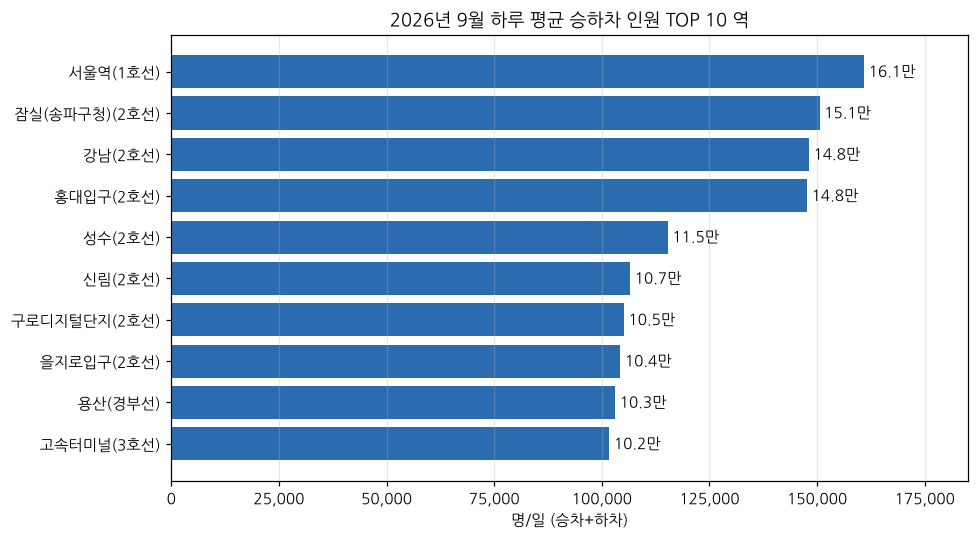

In [5]:
station_total = long.groupby('역(호선)')['일평균'].sum().nlargest(10)
display(station_total.round(0).astype(int).rename('하루 평균 승하차(명/일)').to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
plot_data = station_total.sort_values()               # 작은 값부터 그려야 1위가 맨 위
bars = ax.barh(plot_data.index, plot_data.values, color='#2b6cb0')
ax.bar_label(bars, labels=[f'{v/10000:.1f}만' for v in plot_data.values], padding=3)
ax.set(title='2026년 9월 하루 평균 승하차 인원 TOP 10 역', xlabel='명/일 (승차+하차)')
ax.set_xlim(0, plot_data.max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='x', alpha=.3)
fig.tight_layout(); fig.savefig(OUT / '01_top10_bar.png', dpi=150); plt.show()

## 5단계. 선그래프 — 서울 전체는 언제 지하철을 탈까? (8분)
모든 역을 합쳐 시간대별 승차·하차 인원을 선으로 그립니다. 시간은 **04시부터 다음 날 01시**까지 운행 순서로 배치합니다(02~03시는 거의 0).
- `pivot_table(index='시간', columns='구분', values='일평균', aggfunc='sum')` → 시간 × (승차, 하차) 표
- `reindex(HOUR_ORDER)` → 원하는 시간 순서로 다시 정렬

✅ **확인:** 출근·퇴근의 두 봉우리가 보이나요? 하차가 가장 많은 시간대는 언제인가요?

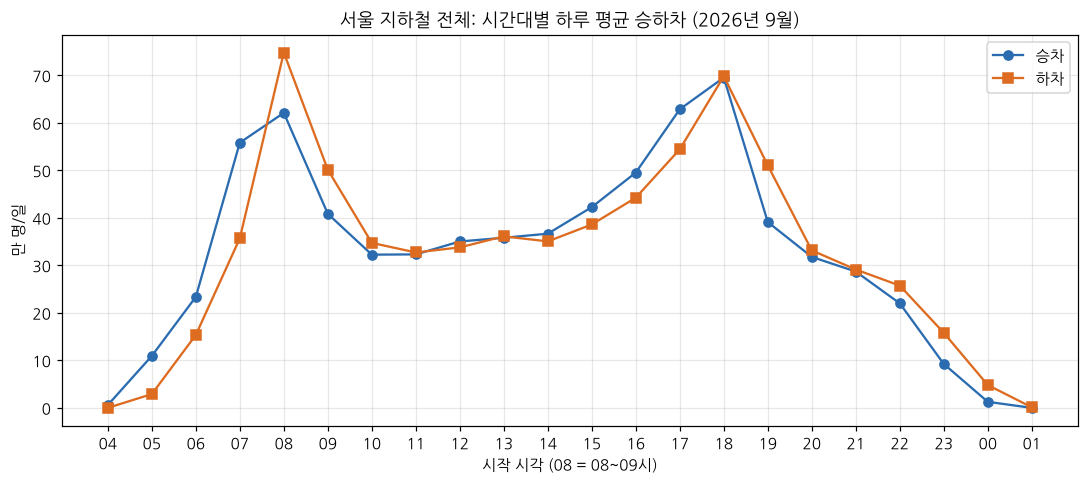

승차 최대: 18~19시, 하루 평균 695,276명
하차 최대: 08~09시, 하루 평균 747,808명


In [6]:
HOUR_ORDER = list(range(4, 24)) + [0, 1]
HOUR_LABELS = [f'{h:02d}' for h in HOUR_ORDER]

seoul_hour = long.pivot_table(index='시간', columns='구분', values='일평균', aggfunc='sum').reindex(HOUR_ORDER)
x = np.arange(len(HOUR_ORDER))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(x, seoul_hour['승차'] / 10000, marker='o', label='승차', color='#2b6cb0')
ax.plot(x, seoul_hour['하차'] / 10000, marker='s', label='하차', color='#dd6b20')
ax.set_xticks(x, HOUR_LABELS)
ax.set(title='서울 지하철 전체: 시간대별 하루 평균 승하차 (2026년 9월)', xlabel='시작 시각 (08 = 08~09시)', ylabel='만 명/일')
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / '02_seoul_hourly_line.png', dpi=150); plt.show()

for kind in ['승차', '하차']:
    h = seoul_hour[kind].idxmax()
    print(f'{kind} 최대: {h:02d}~{h+1:02d}시, 하루 평균 {seoul_hour[kind].max():,.0f}명')

## 6단계. 두 역 비교 — 일하러 가는 역 vs 집으로 가는 역 (10분)
업무 지역(강남)과 주거 지역(신림)의 승차·하차 시간을 나란히 비교합니다.
- **하차가 아침에 많으면** 사람들이 일하러 **도착하는** 역, **승차가 아침에 많으면** 집에서 **출발하는** 역입니다.
- `STATION_A`, `STATION_B`의 이름을 바꿔 다른 역도 비교해 보세요(예: `'홍대입구'`, `'구로디지털단지'`, `'잠실(송파구청)'`). 2호선이 아닌 역은 `LINE_A`, `LINE_B`도 바꿉니다.

✅ **확인:** 두 역의 승차 최대 시각과 하차 최대 시각을 기록 1의 Q2에 적습니다.

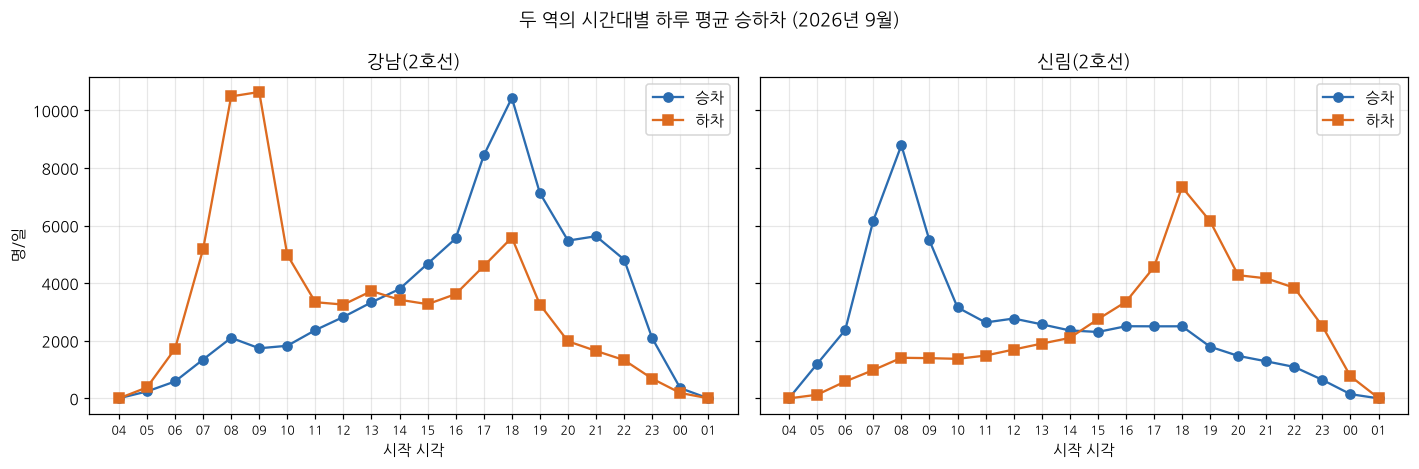

,역,구분,최대 시각,하루 평균(명)
0,강남(2호선),승차,18시,10434
1,강남(2호선),하차,09시,10639
2,신림(2호선),승차,08시,8791
3,신림(2호선),하차,18시,7335


In [7]:
LINE_A, STATION_A = '2호선', '강남'      # ← 바꿔 보기
LINE_B, STATION_B = '2호선', '신림'      # ← 바꿔 보기

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
peak_rows = []
for ax, (line, st) in zip(axes, [(LINE_A, STATION_A), (LINE_B, STATION_B)]):
    one = long[(long['호선명'] == line) & (long['지하철역'] == st)]
    assert len(one) == 48, f'{line} {st} 역을 찾을 수 없습니다. 역 이름을 확인하세요.'
    prof = one.pivot_table(index='시간', columns='구분', values='일평균').reindex(HOUR_ORDER)
    ax.plot(x, prof['승차'], marker='o', label='승차', color='#2b6cb0')
    ax.plot(x, prof['하차'], marker='s', label='하차', color='#dd6b20')
    ax.set_xticks(x, HOUR_LABELS, fontsize=8)
    ax.set(title=f'{st}({line})', xlabel='시작 시각')
    ax.grid(alpha=.3); ax.legend()
    for kind in ['승차', '하차']:
        peak_rows.append({'역': f'{st}({line})', '구분': kind, '최대 시각': f'{prof[kind].idxmax():02d}시',
                          '하루 평균(명)': round(prof[kind].max())})
axes[0].set_ylabel('명/일')
fig.suptitle('두 역의 시간대별 하루 평균 승하차 (2026년 9월)')
fig.tight_layout(); fig.savefig(OUT / '03_two_station_lines.png', dpi=150); plt.show()
display(pd.DataFrame(peak_rows))

## 7단계. 히트맵 — 역 × 시간을 한눈에 (10분)
TOP 15 역의 시간대별 **승차** 인원을 색으로 표시합니다. 행 = 역, 열 = 시간, 색이 진할수록 승차가 많습니다.
- `pivot_table(index='역(호선)', columns='시간', values='일평균')` → 15 × 22 표
- 모든 칸이 **같은 색 기준**(`vmin=0`)이라 역끼리의 크기도 비교됩니다.

✅ **확인:** 아침(07~08시)에 진한 역과 저녁(18시)에 진한 역은 각각 어떤 역인가요? → Q3

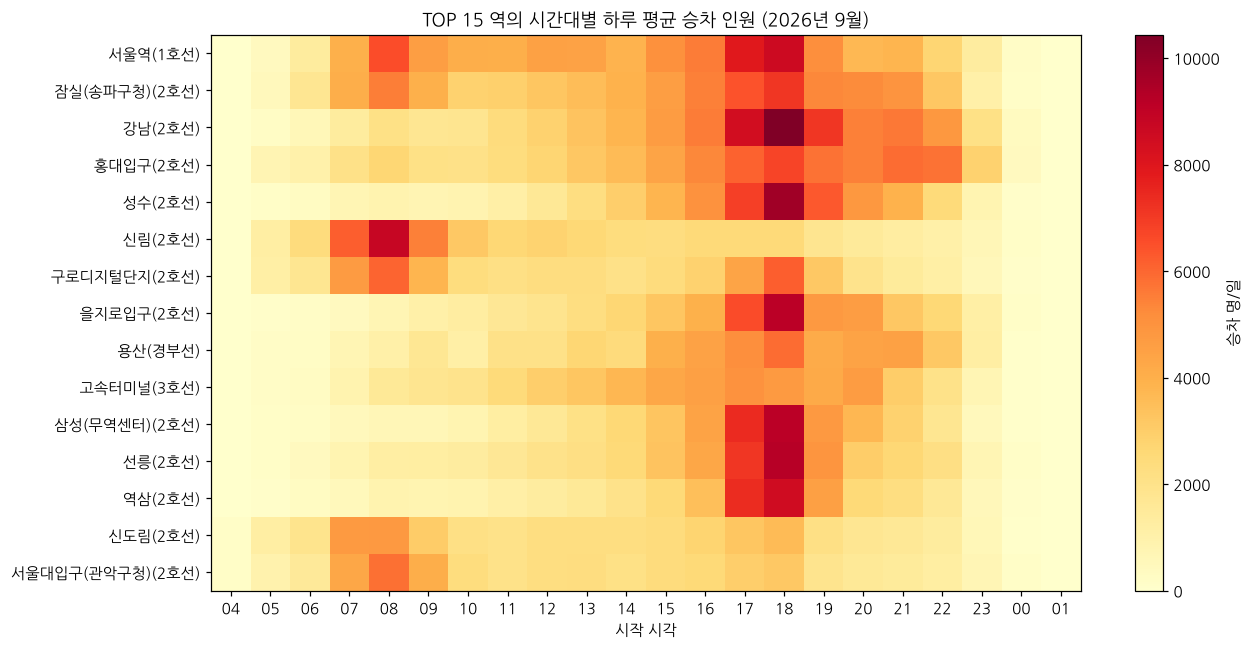

07~08시 승차가 가장 많은 역: 신림(2호선) (6,174명/일)
18~19시 승차가 가장 많은 역: 강남(2호선) (10,434명/일)


In [8]:
top15 = long.groupby('역(호선)')['일평균'].sum().nlargest(15).index
board = long[(long['구분'] == '승차') & (long['역(호선)'].isin(top15))]
heat = board.pivot_table(index='역(호선)', columns='시간', values='일평균').reindex(index=top15, columns=HOUR_ORDER)
assert heat.shape == (15, 22) and not heat.isna().any().any()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(heat, aspect='auto', cmap='YlOrRd', vmin=0)
ax.set_xticks(range(len(HOUR_ORDER)), HOUR_LABELS)
ax.set_yticks(range(len(top15)), top15)
ax.set(title='TOP 15 역의 시간대별 하루 평균 승차 인원 (2026년 9월)', xlabel='시작 시각')
fig.colorbar(im, ax=ax, label='승차 명/일')
fig.tight_layout(); fig.savefig(OUT / '04_station_hour_heatmap.png', dpi=150); plt.show()

print('07~08시 승차가 가장 많은 역:', heat[7].idxmax(), f'({heat[7].max():,.0f}명/일)')
print('18~19시 승차가 가장 많은 역:', heat[18].idxmax(), f'({heat[18].max():,.0f}명/일)')

## ✍️ 기록 1 — 시각화 결과 해석 (5분)
따옴표 안의 안내 문장을 지우고 **그래프와 출력된 숫자를 근거로** 본인의 문장을 씁니다. 실행하면 `answers_part1.json`으로 저장됩니다.

In [9]:
answers1 = {
 "Q1": "2026년 9월 하루 평균 승하차 1위는 서울역(1호선) 약 16.1만 명/일이고, 2위 잠실(송파구청)(2호선) 15.1만, 3위 강남(2호선) 14.8만 명/일이다.",
 "Q2": "강남은 하차가 09시(약 1.06만 명/일), 승차가 18시(약 1.04만 명/일)에 가장 많아 일하러 오는 역이다. 신림은 승차가 08시(약 8,791명/일), 하차가 18시(약 7,335명/일)에 가장 많아 집에서 출발하는 역이다.",
 "Q3": "07~08시 승차는 신림(2호선)이 가장 진하고, 18~19시 승차는 강남·잠실(송파구청) 같은 업무·상업 지역 역이 진하다. 막대는 하루 총량, 히트맵은 언제 많은지를 보여 준다.",
 "Q4": "이 자료는 한 달 합계를 30일로 나눈 평균이라 평일·주말이 섞여 있고, 열차 안에 몇 명이 타고 있는지(정원 대비)는 없다. 그래서 '역 이용 인원'은 알 수 있어도 '열차 혼잡도'는 확정할 수 없다."
}
(OUT / 'answers_part1.json').write_text(json.dumps(answers1, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series(answers1, name='내 답변').to_frame())

,내 답변
Q1,"2026년 9월 하루 평균 승하차 1위는 서울역(1호선) 약 16.1만 명/일이고,..."
Q2,"강남은 하차가 09시(약 1.06만 명/일), 승차가 18시(약 1.04만 명/일)..."
Q3,"07~08시 승차는 신림(2호선)이 가장 진하고, 18~19시 승차는 강남·잠실(송..."
Q4,"이 자료는 한 달 합계를 30일로 나눈 평균이라 평일·주말이 섞여 있고, 열차 안에..."


## 8단계. 진짜 '혼잡도' 데이터 보기 (10분)
서울교통공사 혼잡도는 **열차 정원 대비 실제 탄 사람의 비율(%)**입니다. 30분 동안 그 역을 지나는 열차들의 평균입니다.
- **34%** ≈ 좌석이 모두 찬 상태 · **100%** = 정원만큼 탄 상태 · 150% 이상이면 매우 붐빔
- 2호선은 `내선`(시계 방향 순환)·`외선`(반시계 방향 순환), 다른 호선은 `상선`·`하선`으로 방향을 구분합니다.
- `00시30분` 열은 운행이 끝난 역이 많아 비어 있습니다(결측). 0으로 바꾸지 않고 그대로 둡니다.
- 역번호 9000번대 행(성수·신도림·강동 지선 출발)은 같은 역 이름이 두 번 나와서 이번 실습에서 제외합니다.

✅ **확인:** 강남역 평일 아침과 저녁에 더 붐비는 방향은 각각 무엇인가요? → Q5

30분 시간칸: 39 개 / 5시30분 ~ 00시30분
요일구분: ['평일', '토요일', '일요일'] / 호선: [1, 2, 3, 4, 5, 6, 7, 8]


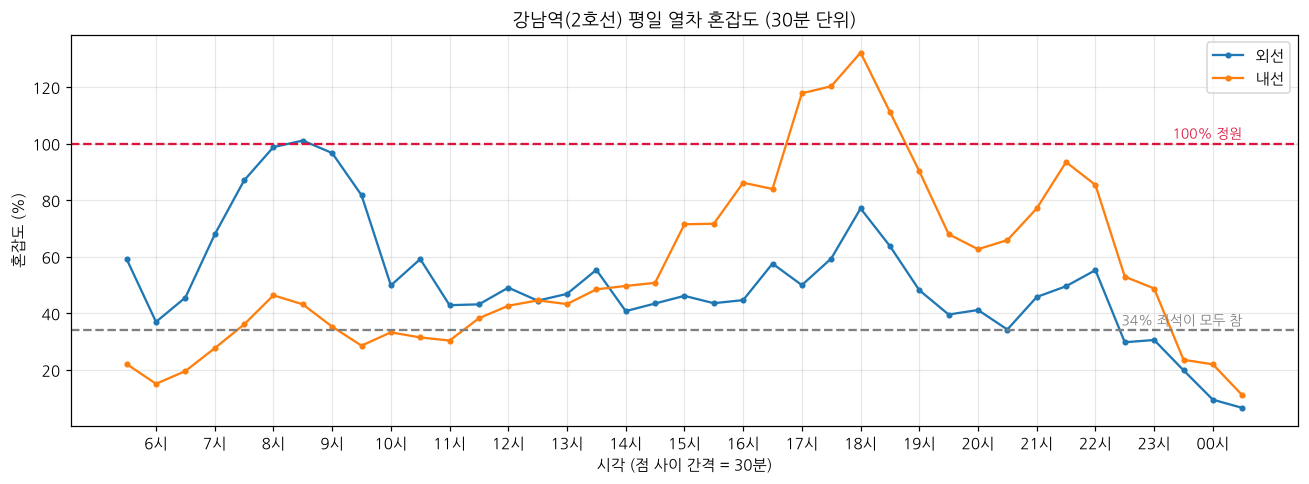

외선: 최고 101.1% (8시30분)
내선: 최고 132.2% (18시00분)


In [10]:
TIME30 = [col for col in cong.columns if re.fullmatch(r'\d+시\d+분', col)]   # '5시30분' ~ '00시30분'
cong = cong[cong['역번호'] < 9000].copy()
print('30분 시간칸:', len(TIME30), '개 /', TIME30[0], '~', TIME30[-1])
print('요일구분:', cong['요일구분'].unique().tolist(), '/ 호선:', sorted(int(v) for v in cong['호선'].unique()))

CONG_LINE, CONG_STATION, DAYTYPE = 2, '강남', '평일'    # ← 바꿔 보기 (예: 2, '사당' / 4, '동대문')
sel = cong[(cong['호선'] == CONG_LINE) & (cong['출발역'] == CONG_STATION) & (cong['요일구분'] == DAYTYPE)]
assert len(sel) > 0, '호선·역 이름을 확인하세요. 혼잡도 자료는 1~8호선만 있습니다.'

fig, ax = plt.subplots(figsize=(12, 4.5))
xs = np.arange(len(TIME30))
for _, row in sel.iterrows():
    ax.plot(xs, row[TIME30].astype(float), marker='.', label=row['상하구분'])
ax.axhline(34, ls='--', color='gray');  ax.text(xs[-1], 36, '34% 좌석이 모두 참', color='gray', fontsize=9, ha='right')
ax.axhline(100, ls='--', color='crimson'); ax.text(xs[-1], 102, '100% 정원', color='crimson', fontsize=9, ha='right')
ax.set_xticks(xs[1::2], [t.replace('시00분', '시') for t in TIME30[1::2]])
ax.set_xlabel('시각 (점 사이 간격 = 30분)')
ax.set(title=f'{CONG_STATION}역({CONG_LINE}호선) {DAYTYPE} 열차 혼잡도 (30분 단위)', ylabel='혼잡도 (%)')
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / '05_congestion_line.png', dpi=150); plt.show()

for _, row in sel.iterrows():
    v = row[TIME30].astype(float)
    print(f"{row['상하구분']}: 최고 {v.max():.1f}% ({v.idxmax()})")

## 9단계. 이용 인원이 많은 역 = 혼잡한 역일까? (10분)
1~8호선 역마다 **평일 08시대 혼잡도**(8시00분·8시30분 평균, 두 방향 중 큰 값)와 **08~09시 하루 평균 승하차 인원**을 짝지어 산점도로 그립니다.
- 역 이름 표기가 조금 달라서 괄호를 지운 이름으로 맞춥니다. 예) `잠실(송파구청)` → `잠실`
- `merge`는 두 표에서 (호선, 역) 이 같은 행끼리 붙입니다.
- **상관계수**는 -1~1 사이 값으로, 1에 가까울수록 한쪽이 클 때 다른 쪽도 크다는 뜻입니다.

✅ **확인:** 점들이 오른쪽 위로 뚜렷하게 모여 있나요? 혼잡도 TOP 역과 이용 인원 TOP 역이 같은가요? → Q6

짝지어진 역: 273 / 상관계수 r = 0.21


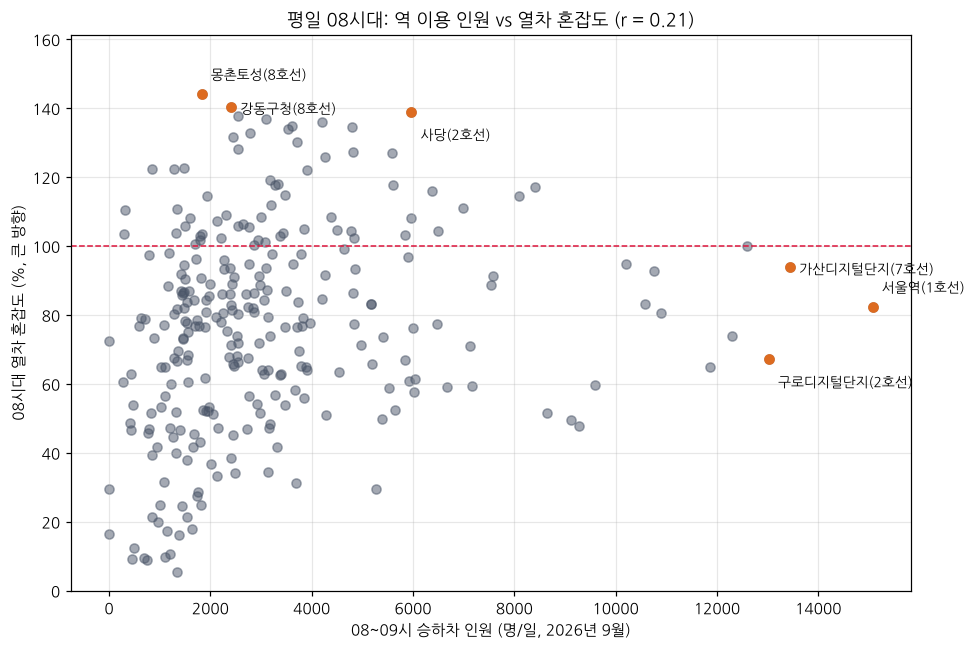


[혼잡도 TOP 5]


,호선,역,혼잡도_08시,이용_08시
260,8,몽촌토성,144.0,1827.6
255,8,강동구청,140.4,2410.6
25,2,사당,139.0,5967.0
115,4,한성대입구,137.8,2548.4
272,8,천호,136.9,3098.6


[이용 인원 TOP 5]


,호선,역,혼잡도_08시,이용_08시
2,1,서울역,82.2,15071.5
213,7,가산디지털단지,93.8,13442.6
14,2,구로디지털단지,67.2,13025.1
10,2,강남,99.9,12588.6
43,2,역삼,74.0,12303.4


In [11]:
def clean_name(s):
    return re.sub(r'\(.*?\)', '', str(s)).strip()

# (1) 혼잡도: 평일 08시대, 방향 중 큰 값
wk = cong[cong['요일구분'] == '평일'].copy()
wk['역'] = wk['출발역'].map(clean_name)
wk['혼잡도_08시'] = wk[['8시00분', '8시30분']].mean(axis=1)
c8 = wk.groupby(['호선', '역'], as_index=False)['혼잡도_08시'].max()

# (2) 이용 인원: 1~8호선, 08~09시 승차+하차 하루 평균
h8 = hourly[hourly['호선명'].str.fullmatch(r'[1-8]호선')].copy()
h8['호선'] = h8['호선명'].str[0].astype(int)
h8['역'] = h8['지하철역'].map(clean_name)
h8['이용_08시'] = (h8['08시-09시 승차인원'] + h8['08시-09시 하차인원']) / DAYS

both = c8.merge(h8[['호선', '역', '이용_08시']], on=['호선', '역'])
r = both['혼잡도_08시'].corr(both['이용_08시'])
print('짝지어진 역:', len(both), '/ 상관계수 r =', round(r, 2))

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(both['이용_08시'], both['혼잡도_08시'], alpha=.5, color='#4a5568')
label_rows = pd.concat([both.nlargest(3, '혼잡도_08시'), both.nlargest(3, '이용_08시')])
for i, (_, row) in enumerate(label_rows.iterrows()):
    ax.scatter(row['이용_08시'], row['혼잡도_08시'], color='#dd6b20', zorder=3)
    ax.annotate(f"{row['역']}({row['호선']}호선)", (row['이용_08시'], row['혼잡도_08시']), fontsize=9,
                xytext=(6, 10 - 14 * (i % 3)), textcoords='offset points')
ax.axhline(100, ls='--', color='crimson', lw=1)
ax.set_ylim(0, both['혼잡도_08시'].max() * 1.12)
ax.set(title=f'평일 08시대: 역 이용 인원 vs 열차 혼잡도 (r = {r:.2f})',
       xlabel='08~09시 승하차 인원 (명/일, 2026년 9월)', ylabel='08시대 열차 혼잡도 (%, 큰 방향)')
ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / '06_usage_vs_congestion.png', dpi=150); plt.show()

print('\n[혼잡도 TOP 5]'); display(both.nlargest(5, '혼잡도_08시').round(1))
print('[이용 인원 TOP 5]'); display(both.nlargest(5, '이용_08시').round(1))

## 10단계. AI로 혼잡도 예측해 보기 (15분)
AI(머신러닝)는 **과거 데이터에서 입력 → 정답의 관계를 학습**해 처음 보는 경우의 값을 예측합니다.
- **목표(정답):** 평일 30분 단위 열차 혼잡도(%)
- **입력:** 시각, 호선, 방향, 그 역의 그 시간 승차·하차 인원(9단계에서 쓴 이용 데이터)
- **평가 방법:** 역의 75%로 학습하고, **학습에 쓰지 않은 25% 역**의 혼잡도를 예측해 실제와 비교합니다.
- **기준값(비교용 단순 방법):** 같은 시각의 학습 역 평균 혼잡도를 그대로 사용
- **MAE(평균 절대 오차):** |예측 − 실제|의 평균. 단위는 %포인트, 작을수록 좋습니다.

모델은 `RandomForestRegressor`(여러 개의 결정나무가 투표하는 방식)를 사용합니다. 실행에 10~30초 걸릴 수 있습니다.

✅ **확인:** AI의 MAE가 기준값보다 얼마나 작은가요? 어떤 입력이 가장 중요하게 쓰였나요? → Q7

학습: 15834 행 / 205 역   평가: 5265 행 / 68 역


,MAE(%p)
기준값(시각 평균),13.80
AI(랜덤포레스트),12.53


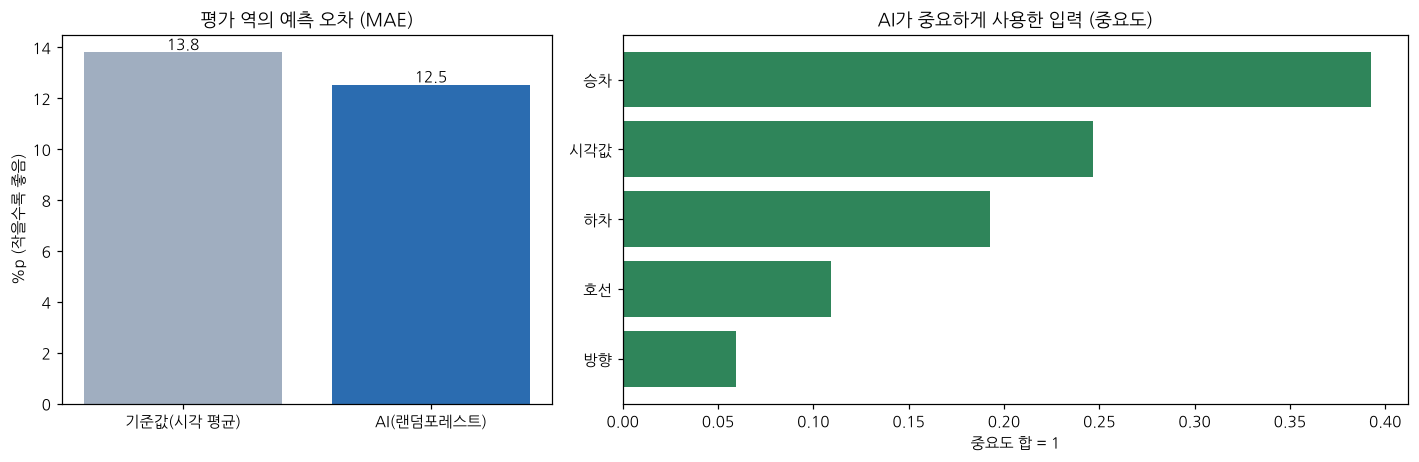

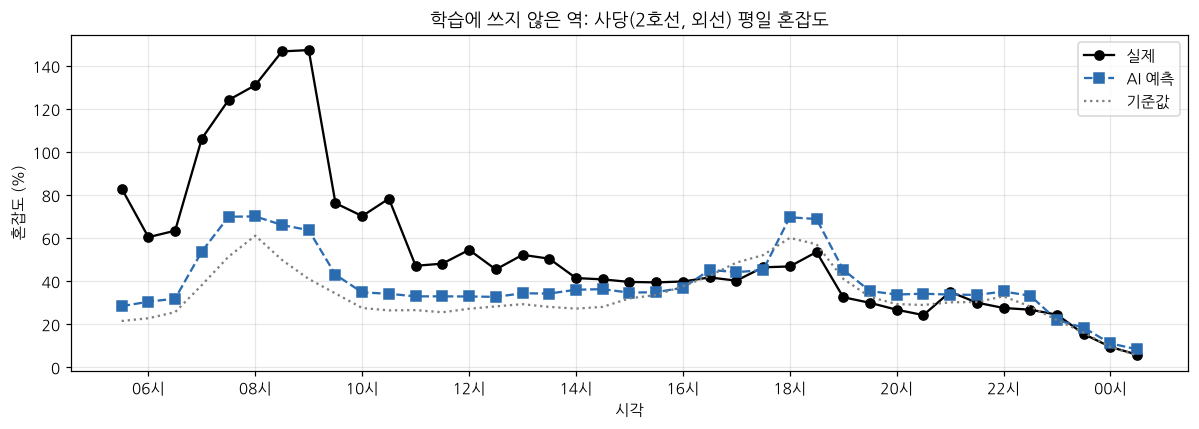

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# (1) 혼잡도를 세로 표로: 한 행 = 호선·역·방향·30분 시각
cl = wk.melt(id_vars=['호선', '역', '상하구분'], value_vars=TIME30, var_name='시각', value_name='혼잡도').dropna()
cl['시'] = cl['시각'].str.extract(r'^(\d+)시')[0].astype(int)
cl['시각값'] = cl['시'] + np.where(cl['시각'].str.contains('30분'), 0.5, 0) + np.where(cl['시'] == 0, 24, 0)
cl['방향'] = cl['상하구분'].map({'상선': 0, '내선': 0, '하선': 1, '외선': 1})

# (2) 같은 역·같은 시(hour)의 승차·하차 인원 붙이기
h8_long = long[long['호선명'].str.fullmatch(r'[1-8]호선')].copy()
h8_long['호선'] = h8_long['호선명'].str[0].astype(int)
h8_long['역'] = h8_long['지하철역'].map(clean_name)
hp = h8_long.pivot_table(index=['호선', '역', '시간'], columns='구분', values='일평균').reset_index()
data = cl.merge(hp, left_on=['호선', '역', '시'], right_on=['호선', '역', '시간'])

# (3) 역 단위로 학습/평가 나누기 (같은 역이 양쪽에 섞이지 않게)
stations = data[['호선', '역']].drop_duplicates()
test_st = stations.sample(frac=0.25, random_state=2026)
is_test = data.set_index(['호선', '역']).index.isin(test_st.set_index(['호선', '역']).index)
train, test = data[~is_test], data[is_test].copy()
print('학습:', len(train), '행 /', len(stations) - len(test_st), '역   평가:', len(test), '행 /', len(test_st), '역')

# (4) 기준값과 AI 모델
test['기준값'] = test['시각값'].map(train.groupby('시각값')['혼잡도'].mean())
FEATURES = ['시각값', '호선', '방향', '승차', '하차']
model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=2026, n_jobs=-1)
model.fit(train[FEATURES], train['혼잡도'])
test['AI예측'] = model.predict(test[FEATURES])

mae = pd.Series({'기준값(시각 평균)': mean_absolute_error(test['혼잡도'], test['기준값']),
                 'AI(랜덤포레스트)': mean_absolute_error(test['혼잡도'], test['AI예측'])})
display(mae.round(2).rename('MAE(%p)').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.6]})
axes[0].bar(mae.index, mae.values, color=['#a0aec0', '#2b6cb0'])
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')
axes[0].set(title='평가 역의 예측 오차 (MAE)', ylabel='%p (작을수록 좋음)')
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
axes[1].barh(imp.index, imp.values, color='#2f855a')
axes[1].set(title='AI가 중요하게 사용한 입력 (중요도)', xlabel='중요도 합 = 1')
fig.tight_layout(); fig.savefig(OUT / '07_ai_mae_importance.png', dpi=150); plt.show()

# (5) 평가 역 하나: 실제 vs 예측
ex = test.groupby(['호선', '역', '상하구분'])['혼잡도'].max().idxmax()      # 평가 역 중 가장 붐비는 곳
one = test[(test['호선'] == ex[0]) & (test['역'] == ex[1]) & (test['상하구분'] == ex[2])].sort_values('시각값')
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(one['시각값'], one['혼잡도'], 'o-', label='실제', color='black')
ax.plot(one['시각값'], one['AI예측'], 's--', label='AI 예측', color='#2b6cb0')
ax.plot(one['시각값'], one['기준값'], ':', label='기준값', color='gray')
ax.set(title=f'학습에 쓰지 않은 역: {ex[1]}({ex[0]}호선, {ex[2]}) 평일 혼잡도', xlabel='시각', ylabel='혼잡도 (%)')
ax.set_xticks(range(6, 25, 2), [f'{h % 24:02d}시' for h in range(6, 25, 2)])
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / '08_ai_example_station.png', dpi=150); plt.show()
pd.DataFrame({'MAE': mae}).to_csv(OUT / 'ai_mae.csv', encoding='utf-8-sig')

## 11단계. 실제 AI 혼잡도 예측 서비스와 비교 (15분)
**서울 실시간 도시데이터**(https://data.seoul.go.kr/SeoulRtd/)는 KT 통신 신호로 추정한 **주요 121장소의 실시간 인구**와 AI가 예측한 **향후 12시간 인구·혼잡도 단계**(여유 · 보통 · 약간 붐빔 · 붐빔)를 보여 줍니다.

1. 아래 셀을 실행해 오늘 분석한 역이 121장소에 있는지 확인합니다.
2. 사이트에서 장소(예: `강남역`)를 검색하고 **현재 혼잡도 단계, 인구 범위, 예측 그래프**를 확인합니다.
3. 아래 기록 셀의 `service` 항목을 화면에서 본 그대로 적습니다. 화면에 없는 값은 `'미제공'`, 접속이 안 되면 `'접속 불가'`로 적습니다.

| 비교 | 오늘 실습 데이터 | 실시간 도시데이터 AI 예측 |
|---|---|---|
| 무엇을 세나 | 역 개찰구 승하차 / 열차 안 혼잡도 | 장소(역 주변 구역)에 머무는 인구 |
| 시점 | 2026년 9월 한 달 평균 / 2025년 3월 기준 | 지금 + 앞으로 12시간 |
| 단위 | 명/일, % | 인구 범위(명), 4단계 |
| AI 역할 | 10단계에서 직접 학습·평가 | 서비스가 학습한 모델이 예측 |

In [13]:
MY_STATIONS = ['강남역', '신림역', '홍대입구역', '잠실역', '서울역']           # ← 오늘 본 역으로 바꿔 보기
hit = places[places['AREA_NM'].str.contains('|'.join(MY_STATIONS))]
display(hit[['CATEGORY', 'AREA_CD', 'AREA_NM']])
print('실시간 도시데이터 바로가기: https://data.seoul.go.kr/SeoulRtd/')

,CATEGORY,AREA_CD,AREA_NM
13,인구밀집지역,POI014,강남역
30,인구밀집지역,POI033,서울역
36,인구밀집지역,POI039,신림역
52,인구밀집지역,POI055,홍대입구역(2호선)
108,인구밀집지역,POI119,잠실역


실시간 도시데이터 바로가기: https://data.seoul.go.kr/SeoulRtd/


## ✍️ 기록 2 — 혼잡도·AI 비교 (10분)
`service`에는 실시간 도시데이터 화면에서 본 값을, `answers2`에는 Q5~Q8 답변을 씁니다.

In [14]:
service = {
 "조회일시": "2026-11-19 19:40 (예시)",
 "장소": "강남역",
 "현재_혼잡도단계": "약간 붐빔 (예시: 실제 화면 값으로 작성)",
 "현재_인구범위": "예시: 화면에 표시된 범위",
 "예측_가장붐비는시각": "예시: 화면의 예측 그래프에서 확인",
 "예측_단계": "예시"
}
answers2 = {
 "Q5": "강남역 평일 외선은 8시30분 101.1%로 아침에 가장 붐비고, 내선은 18시00분 132.2%로 저녁에 가장 붐빈다. 아침과 저녁에 붐비는 방향이 반대다.",
 "Q6": "상관계수는 약 0.2로 약하다. 이용 인원 1위권(서울역·가산디지털단지·구로디지털단지)과 혼잡도 1위권(몽촌토성·강동구청·사당)이 다르다. 열차 혼잡은 그 역에서 타고 내리는 사람보다 이미 열차 안에 타고 지나가는 사람에 더 크게 좌우되기 때문이다.",
 "Q7": "AI의 MAE(약 12.5%p)가 기준값(약 13.8%p)보다 작지만 차이는 1%p 정도로 크지 않다. 중요도는 승차 인원과 시각이 높았다. 평가 역 사당(2호선 외선)은 아침 실제 혼잡도가 140%가 넘는데 AI는 70% 정도로 크게 낮게 예측했다. 역 이용 인원만으로는 열차 안 인원을 알 수 없어, 실제 서비스처럼 실시간 열차 하중이나 통신 데이터 같은 입력이 더 필요하다.",
 "Q8": "실시간 도시데이터는 지금과 12시간 뒤의 장소 인구를 알려 주고, 오늘 데이터는 한 달 평균 패턴을 알려 준다. 출발 전 그래프로 피해야 할 시간대를 정하고, 당일에는 서비스 예측 단계를 확인해 출발 시간을 조정한다. 서비스 정확도를 확인하려면 예측값을 저장해 두었다가 같은 장소·시각의 실제 값과 비교해야 한다."
}
(OUT / 'service_record.json').write_text(json.dumps(service, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / 'answers_part2.json').write_text(json.dumps(answers2, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.Series(service, name='서비스 조회 기록').to_frame())
display(pd.Series(answers2, name='내 답변').to_frame())

,서비스 조회 기록
조회일시,2026-11-19 19:40 (예시)
장소,강남역
현재_혼잡도단계,약간 붐빔 (예시: 실제 화면 값으로 작성)
현재_인구범위,예시: 화면에 표시된 범위
예측_가장붐비는시각,예시: 화면의 예측 그래프에서 확인
예측_단계,예시


,내 답변
Q5,"강남역 평일 외선은 8시30분 101.1%로 아침에 가장 붐비고, 내선은 18시00..."
Q6,상관계수는 약 0.2로 약하다. 이용 인원 1위권(서울역·가산디지털단지·구로디지털단...
Q7,AI의 MAE(약 12.5%p)가 기준값(약 13.8%p)보다 작지만 차이는 1%p...
Q8,"실시간 도시데이터는 지금과 12시간 뒤의 장소 인구를 알려 주고, 오늘 데이터는 한..."


## 12단계. 제출 파일 만들기 (5분)
1. 학번·이름을 적고 아래 셀을 실행하면 `Week10_학번_이름.zip`이 만들어집니다(그림 8장 + 답변 3개 + MAE 표).
2. Colab 왼쪽 📁 파일 목록에서 ZIP을 내려받습니다.
3. `파일 → 다운로드 → .ipynb 다운로드`로 노트북도 받습니다.
4. **ipynb + ZIP**을 수업 제출처에 올립니다.

In [15]:
STUDENT = {'학번': '2026000000', '이름': '홍길동'}
needed = ['01_top10_bar.png', '02_seoul_hourly_line.png', '03_two_station_lines.png', '04_station_hour_heatmap.png',
          '05_congestion_line.png', '06_usage_vs_congestion.png', '07_ai_mae_importance.png', '08_ai_example_station.png',
          'answers_part1.json', 'answers_part2.json', 'service_record.json', 'ai_mae.csv']
missing = [f for f in needed if not (OUT / f).exists()]
assert not missing, f'아직 만들어지지 않은 파일: {missing} → 앞 단계를 실행하세요.'
(OUT / 'student_info.json').write_text(json.dumps(STUDENT, ensure_ascii=False), encoding='utf-8')
zip_path = shutil.make_archive(f"Week10_{STUDENT['학번']}_{STUDENT['이름']}", 'zip', OUT)
print('✔ 제출 ZIP 생성:', Path(zip_path).name, '/ 파일', len(list(OUT.iterdir())), '개')

✔ 제출 ZIP 생성: Week10_2026000000_홍길동.zip / 파일 13 개
